# Evaluating LLM Classification Tasks

This tutorial compares one classification adapter across sentiment, market-sentiment, and spam fixtures. It defaults to deterministic offline predictions and optionally uses the current OpenAI Responses API. No credentials or billable calls are required for the default run.

In [1]:
from pathlib import Path
import os

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from sklearn.metrics import accuracy_score, confusion_matrix, f1_score

LIVE_API = os.getenv('RUN_LIVE_OPENAI', '0') == '1'
MODEL = os.getenv('OPENAI_TEXT_MODEL', 'gpt-4.1-mini')
OUTPUT_DIR = Path('generated/openai-602')
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

tasks = {
    'general sentiment': pd.DataFrame([
        ('I love how simple this update is', 'positive'),
        ('The service failed again', 'negative'),
        ('The package arrived today', 'neutral'),
        ('Support solved my problem quickly', 'positive'),
        ('Nothing changed after the release', 'neutral'),
        ('The new workflow is frustrating', 'negative'),
    ], columns=['text', 'label']),
    'market sentiment': pd.DataFrame([
        ('Guidance was raised after strong demand', 'positive'),
        ('The company warned about lower revenue', 'negative'),
        ('Shares closed unchanged after the filing', 'neutral'),
        ('Margins expanded beyond expectations', 'positive'),
        ('Management expects a material loss', 'negative'),
        ('The annual meeting starts on Tuesday', 'neutral'),
    ], columns=['text', 'label']),
    'email spam': pd.DataFrame([
        ('Claim your free prize now', 'spam'),
        ('Minutes from the project meeting', 'ham'),
        ('Urgent: verify your account password', 'spam'),
        ('Lunch moved to 12:30', 'ham'),
        ('Exclusive cash offer click today', 'spam'),
        ('Draft contract attached for review', 'ham'),
    ], columns=['text', 'label']),
}
print('mode:', 'live OpenAI API' if LIVE_API else 'deterministic offline fixture')

mode: deterministic offline fixture


## 1. Define Offline and Live Classifiers

The live adapter sends one item at a time with an explicit allowed-label list. Returned text is validated before evaluation.

In [2]:
offline_predictions = {
    'general sentiment': ['positive', 'negative', 'neutral', 'positive', 'neutral', 'negative'],
    'market sentiment': ['positive', 'negative', 'neutral', 'positive', 'negative', 'neutral'],
    'email spam': ['spam', 'ham', 'spam', 'ham', 'spam', 'ham'],
}

def classify(task_name, data):
    if not LIVE_API:
        return offline_predictions[task_name]

    from openai import OpenAI
    client = OpenAI()
    allowed = sorted(data['label'].unique())
    predictions = []
    for text in data['text']:
        response = client.responses.create(
            model=MODEL,
            input=(
                f'Classify the text for {task_name}. Return exactly one label from {allowed}. '
                f'Text: {text}'
            ),
        )
        label = response.output_text.strip().lower()
        if label not in allowed:
            raise ValueError(f'Unexpected label: {label!r}')
        predictions.append(label)
    return predictions

## 2. Evaluate Every Task Consistently

Macro F1 gives each class equal weight. Accuracy is included for familiarity, and a majority-class macro F1 provides a simple baseline.

In [3]:
rows = []
confusion_matrices = {}
for task_name, data in tasks.items():
    predictions = classify(task_name, data)
    majority_label = data['label'].mode().iloc[0]
    majority_predictions = [majority_label] * len(data)
    labels = sorted(data['label'].unique())
    rows.append({
        'task': task_name,
        'macro_f1': f1_score(data['label'], predictions, average='macro'),
        'accuracy': accuracy_score(data['label'], predictions),
        'majority_macro_f1': f1_score(data['label'], majority_predictions, average='macro'),
    })
    confusion_matrices[task_name] = (labels, confusion_matrix(data['label'], predictions, labels=labels))

metrics = pd.DataFrame(rows).set_index('task')
print(metrics.round(3).to_string())
assert metrics['macro_f1'].ge(metrics['majority_macro_f1']).all()

                   macro_f1  accuracy  majority_macro_f1
task                                                    
general sentiment       1.0       1.0              0.167
market sentiment        1.0       1.0              0.167
email spam              1.0       1.0              0.333


## 3. Compare Results and Inspect Errors

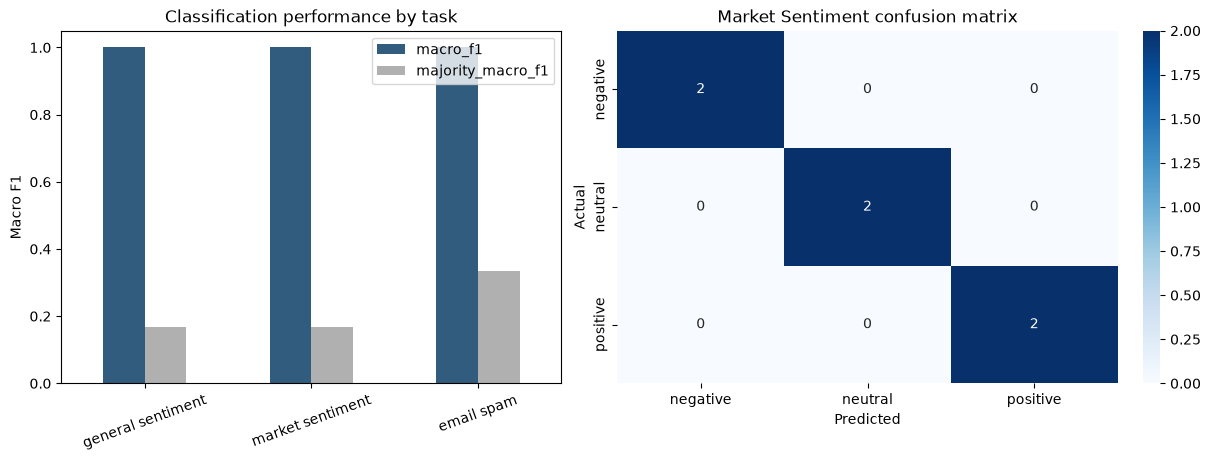

saved: generated\openai-602\llm-classification-comparison.png


In [4]:
figure, axes = plt.subplots(1, 2, figsize=(12, 4.5), constrained_layout=True)
metrics[['macro_f1', 'majority_macro_f1']].plot.bar(color=['#315c7d', '#b0b0b0'], ax=axes[0])
axes[0].set(title='Classification performance by task', ylabel='Macro F1', ylim=(0, 1.05), xlabel=None)
axes[0].tick_params(axis='x', rotation=20)
task_name = 'market sentiment'
labels, matrix = confusion_matrices[task_name]
sns.heatmap(matrix, annot=True, fmt='d', cmap='Blues', xticklabels=labels, yticklabels=labels, ax=axes[1])
axes[1].set(title=f'{task_name.title()} confusion matrix', xlabel='Predicted', ylabel='Actual')
figure_path = OUTPUT_DIR / 'llm-classification-comparison.png'
figure.savefig(figure_path, dpi=170, bbox_inches='tight')
plt.show()
print(f'saved: {figure_path}')

## 4. Evaluation Limits

The offline fixture verifies the pipeline, not model quality. A real benchmark needs a larger frozen test set, representative class prevalence, prompt and model version tracking, repeated runs for nondeterministic models, cost and latency measurements, and manual review of consequential errors.